In [54]:
## 1. Environment and reproducibility

In [55]:
## Required libraries.
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os
import platform
import copy

from torch.utils.data import TensorDataset, DataLoader

from torch.profiler import (
    profile,
    record_function,
    ProfilerActivity
)

from sklearn.metrics import accuracy_score
import random, json, shutil, html, joblib
from pathlib import Path
from sklearn.metrics import classification_report, f1_score
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(RANDOM_STATE)
OUT = Path("profiling_results")
OUT.mkdir(exist_ok=True)

In [56]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", device)
print("Operating System:", platform.system())
print("CPU Cores:", os.cpu_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )
(OUT / "environment.json").write_text(json.dumps(dict(torch=torch.__version__, device=str(device), cpu_cores=os.cpu_count(), threads=torch.get_num_threads(), gpu=torch.cuda.get_device_name(0) if device.type=="cuda" else None), indent=2))

PyTorch Version: 2.14.1+cpu
Device: cpu
Operating System: Linux
CPU Cores: 2


95

In [57]:
## 2. Load existing IMDB dataset

In [58]:
USE_GCS = True
LOCAL_RAW_PATH = "IMDB Dataset.csv"
if USE_GCS:

    from google.colab import auth
    from google.cloud import storage

    # Authenticate the current Colab session with Google Cloud.
    auth.authenticate_user()

    # -----------------------------
    # GCP configuration
    # -----------------------------
    PROJECT_ID = "dh-and-infra-for-ai"
    BUCKET_NAME = "imdb-sentiment-project"
    LOCATION = "EU"

    # GCS locations
    RAW_GCS_PATH = "raw/IMDB Dataset.csv"
    SHARDED_PREFIX = "sharded"

    # Local working paths
    LOCAL_RAW_PATH = "IMDB Dataset.csv"
    LOCAL_SHARDS_FOLDER = "shards"

    print(f"Project: {PROJECT_ID}")
    print(f"Bucket: gs://{BUCKET_NAME}")
    print(f"Raw object: gs://{BUCKET_NAME}/{RAW_GCS_PATH}")
    storage_client = storage.Client(project=PROJECT_ID)
    bucket = storage_client.bucket(BUCKET_NAME)

    if not storage_client.lookup_bucket(BUCKET_NAME):
        raise ValueError(
            f"Bucket gs://{BUCKET_NAME} was not found or is not accessible."
        )

    print(f"Connected successfully to gs://{BUCKET_NAME}")
    blob = bucket.blob(RAW_GCS_PATH)

    if not blob.exists():
        raise FileNotFoundError(
            f"Raw dataset not found at gs://{BUCKET_NAME}/{RAW_GCS_PATH}"
        )

    blob.download_to_filename(LOCAL_RAW_PATH)

    print(f"Downloaded gs://{BUCKET_NAME}/{RAW_GCS_PATH}")
    print(f"Saved locally as: {LOCAL_RAW_PATH}")
    print(f"File size: {os.path.getsize(LOCAL_RAW_PATH):,} bytes")
else:
    from google.colab import files
    uploaded = files.upload()
    LOCAL_RAW_PATH = next(iter(uploaded))
from sklearn.model_selection import train_test_split

Project: dh-and-infra-for-ai
Bucket: gs://imdb-sentiment-project
Raw object: gs://imdb-sentiment-project/raw/IMDB Dataset.csv
Connected successfully to gs://imdb-sentiment-project
Downloaded gs://imdb-sentiment-project/raw/IMDB Dataset.csv
Saved locally as: IMDB Dataset.csv
File size: 66,497,315 bytes


In [59]:
df = pd.read_csv(
    LOCAL_RAW_PATH,
    encoding="utf-8"
)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

expected_columns = {"review", "sentiment"}
missing_columns = expected_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

# Keep only the expected project columns if extra columns are present.
df = df[["review", "sentiment"]].copy()

display(df.head())

Dataset shape: (50000, 3)
Columns: ['review', 'sentiment', 'split']


,review,sentiment
0,I caught this little gem totally by accident b...,positive
1,I can't believe that I let myself into this mo...,negative
2,*spoiler alert!* it just gets to me the nerve ...,negative
3,If there's one thing I've learnt from watching...,negative
4,"I remember when this was in theaters, reviews ...",negative


In [60]:
## 3. Clean text and encode labels

In [61]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
for resource in ["stopwords", "wordnet", "omw-1.4"]: nltk.download(resource, quiet=True)
stop_words = set(stopwords.words('english'))

# Retain important sentiment-related negation words
stop_words = stop_words - {'not', 'no', 'nor', 'never'}

lemmatizer = WordNetLemmatizer()


def clean_text(text):

    # Convert to lowercase
    text = html.unescape(str(text)).lower().replace('’', "'")
    text = text.replace("can't", "can not").replace("won't", "will not")

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Expand common negation contractions
    text = re.sub(r"n't\b", " not", text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    words = text.split()

    # Remove stopwords and apply lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [62]:
before = len(df)
df = df.dropna(subset=["review", "sentiment"]).copy()
df["sentiment"] = df["sentiment"].str.strip().str.lower()
## Encode the target variable

df['sentiment_encoded'] = df['sentiment'].map({
    'negative': 0,
    'positive': 1
})

assert df['sentiment_encoded'].notna().all(), \
    "Unexpected sentiment labels found."

df['sentiment_encoded'] = df['sentiment_encoded'].astype(int)


df["cleaned_review"] = df["review"].apply(clean_text)
df = df[df.cleaned_review.str.strip().ne("")].copy()
conflicts = df.groupby("cleaned_review").sentiment_encoded.transform("nunique") > 1
df = df.loc[~conflicts].drop_duplicates("cleaned_review").reset_index(drop=True)
print(f"Removed {before-len(df)} rows; retained {len(df)}")

Removed 426 rows; retained 49574


In [63]:
## 4. Stratified train / development / test split (70/15/15)
## Development data is used for model selection and optimisation. Test data is reserved for final evaluation.

In [64]:
# ============================================================
# SPLIT DATASET INTO TRAINING, DEVELOPMENT AND TESTING SETS
# ============================================================
# ------------------------------------------------------------
# Define input features and target variable
# ------------------------------------------------------------

RANDOM_STATE = 42
X = df["cleaned_review"]
y = df["sentiment_encoded"]


# ------------------------------------------------------------
# First split: Training (70%) and Temporary (30%)
# ------------------------------------------------------------

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)


# ------------------------------------------------------------
# Second split: Development (15%) and Testing (15%)
# ------------------------------------------------------------

X_dev_text, X_test_text, y_dev, y_test = train_test_split(
    X_temp_text,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)


# ------------------------------------------------------------
# Display dataset sizes
# ------------------------------------------------------------

print("Total Reviews:", len(X))

print("\nTraining Reviews:", len(X_train_text))
print("Development Reviews:", len(X_dev_text))
print("Testing Reviews:", len(X_test_text))


# ------------------------------------------------------------
# Display sentiment distribution
# ------------------------------------------------------------

print("\nTraining Sentiment Distribution:")
print(y_train.value_counts())

print("\nDevelopment Sentiment Distribution:")
print(y_dev.value_counts())

print("\nTesting Sentiment Distribution:")
print(y_test.value_counts())


# ------------------------------------------------------------
# Create dataset split summary
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    "Dataset": [
        "Training",
        "Development",
        "Testing"
    ],
    "Total Reviews": [
        len(y_train),
        len(y_dev),
        len(y_test)
    ],
    "Percentage (%)": [
        len(y_train) / len(y) * 100,
        len(y_dev) / len(y) * 100,
        len(y_test) / len(y) * 100
    ],
    "Positive Reviews": [
        (y_train == 1).sum(),
        (y_dev == 1).sum(),
        (y_test == 1).sum()
    ],
    "Negative Reviews": [
        (y_train == 0).sum(),
        (y_dev == 0).sum(),
        (y_test == 0).sum()
    ]
})

display(split_summary.round(2))


# ------------------------------------------------------------
# 6.7 Validate dataset splits
# ------------------------------------------------------------

assert len(X_train_text) + len(X_dev_text) + len(X_test_text) == len(X)

assert set(X_train_text.index).isdisjoint(X_dev_text.index)
assert set(X_train_text.index).isdisjoint(X_test_text.index)
assert set(X_dev_text.index).isdisjoint(X_test_text.index)

print("\nDataset split validation successful.")
print("No overlapping row indices between datasets.")
split_summary.to_csv(OUT / "split_summary.csv", index=False)

Total Reviews: 49574

Training Reviews: 34701
Development Reviews: 7436
Testing Reviews: 7437

Training Sentiment Distribution:
sentiment_encoded
1    17415
0    17286
Name: count, dtype: int64

Development Sentiment Distribution:
sentiment_encoded
1    3732
0    3704
Name: count, dtype: int64

Testing Sentiment Distribution:
sentiment_encoded
1    3732
0    3705
Name: count, dtype: int64


,Dataset,Total Reviews,Percentage (%),Positive Reviews,Negative Reviews
0,Training,34701,70.0,17415,17286
1,Development,7436,15.0,3732,3704
2,Testing,7437,15.0,3732,3705



Dataset split validation successful.
No overlapping row indices between datasets.


In [65]:
## 5. TF-IDF feature extraction
## Keep 5,000-feature unigram configuration; float32 halves feature storage relative to float64. Fit on training only.

In [66]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000, dtype=np.float32)

# Fit and transform training data
X_train = tfidf_vectorizer.fit_transform(X_train_text)

# Transform development data
X_dev = tfidf_vectorizer.transform(X_dev_text)

# Transform testing data
X_test = tfidf_vectorizer.transform(X_test_text)

# Display feature dimensions
print("Training Features Shape:", X_train.shape)
print("Development Features Shape:", X_dev.shape)
print("Testing Features Shape:", X_test.shape)
for name, x in [("train",X_train),("dev",X_dev),("test",X_test)]:
    print(name, "CSR MiB:", round((x.data.nbytes+x.indices.nbytes+x.indptr.nbytes)/2**20,2), "dense MiB:", round(np.prod(x.shape)*4/2**20,2))

Training Features Shape: (34701, 5000)
Development Features Shape: (7436, 5000)
Testing Features Shape: (7437, 5000)
train CSR MiB: 21.44 dense MiB: 661.87
dev CSR MiB: 4.58 dense MiB: 141.83
test CSR MiB: 4.58 dense MiB: 141.85


In [67]:
## 6. PyTorch datasets and loaders

Fix the undefined prepare_dataset helper. Baseline uses dense CPU tensors, never the entire dataset on GPU. At 50,000 × 5,000 float32 values this requires about 954 MiB of host memory. If RAM is insufficient, reduce the dataset size consistently before splitting or use a sparse batch loader and document the changed baseline.

In [68]:
def prepare_dataset(X, y, sample_size=None):
    size = len(y) if sample_size is None else min(sample_size, len(y))
    labels = np.asarray(y, dtype=np.float32).reshape(-1,1)
    assert X.shape[0] == len(labels)
    return TensorDataset(torch.from_numpy(X[:size].toarray().astype(np.float32, copy=False)), torch.from_numpy(labels[:size]))
# Create PyTorch datasets using the prepared helper function
train_dataset = prepare_dataset(X_train, y_train, sample_size=len(y_train))
dev_dataset = prepare_dataset(X_dev, y_dev, sample_size=len(y_dev))
test_dataset = prepare_dataset(X_test, y_test, sample_size=len(y_test))

print("Training Dataset Size:", len(train_dataset))
print("Development Dataset Size:", len(dev_dataset))
print("Testing Dataset Size:", len(test_dataset))

Training Dataset Size: 34701
Development Dataset Size: 7436
Testing Dataset Size: 7437


In [69]:
BATCH_SIZE = 64

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    generator=torch.Generator().manual_seed(RANDOM_STATE)
)

# Development DataLoader
dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Training Batches:", len(train_loader))
print("Development Batches:", len(dev_loader))
print("Testing Batches:", len(test_loader))
xb,yb = next(iter(train_loader))
print(xb.shape, yb.shape, xb.dtype)

Training Batches: 543
Development Batches: 117
Testing Batches: 117
torch.Size([64, 5000]) torch.Size([64, 1]) torch.float32


In [70]:
## 7. ANN/MLP architecture and training

Proposed baseline: 256 and 128 hidden units, ReLU, dropout 0.3, one output logit. BCEWithLogitsLoss includes sigmoid internally. Choose the checkpoint with lowest development loss; do not tune on test data.

IMDBMLP(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)
Parameters: 1313281
{'epoch': 1, 'train_loss': 0.32869424162828315, 'train_accuracy': 0.8618483617186825, 'dev_loss': 0.25870130565809013, 'dev_accuracy': 0.8920118343195266, 'train_seconds': 11.197866995997174}
{'epoch': 2, 'train_loss': 0.22546665901963123, 'train_accuracy': 0.9101754992651508, 'dev_loss': 0.27009144180913713, 'dev_accuracy': 0.8863636363636364, 'train_seconds': 11.15105246299936}
{'epoch': 3, 'train_loss': 0.1792483982665474, 'train_accuracy': 0.9323938791389297, 'dev_loss': 0.28373653859685605, 'dev_accuracy': 0.8854222700376546, 'train_seconds': 10.170800462998159}
{'epoch': 4, 'train_loss': 0.11395457623020441, 'train_accuracy': 0.961

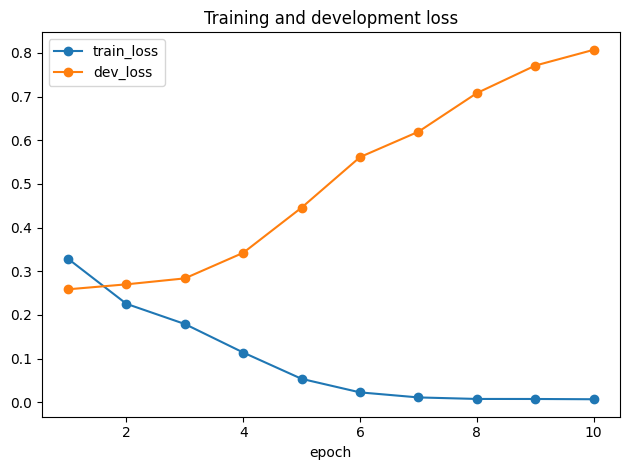

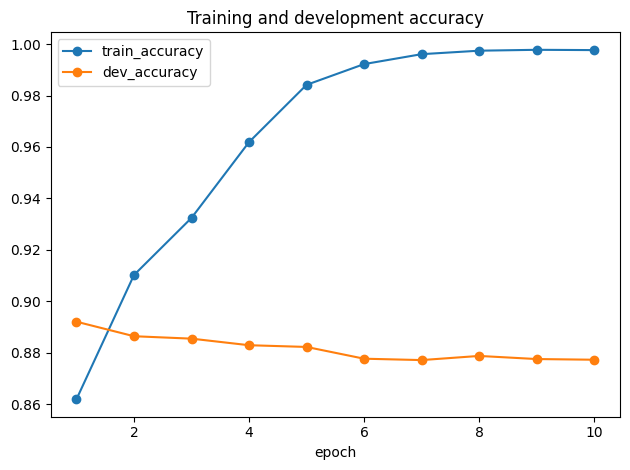

In [71]:
class IMDBMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size,256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256,128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128,1))
    def forward(self,x): return self.network(x)

model = IMDBMLP(X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 10
print(model)
print('Parameters:', sum(p.numel() for p in model.parameters()))
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()

def evaluate(loader):
    model.eval()
    loss_sum = correct = count = 0
    with torch.inference_mode():
        for x,y in loader:
            x,y = x.to(device),y.to(device)
            z = model(x)
            loss_sum += criterion(z,y).item()*len(y)
            correct += ((z>=0)==y.bool()).sum().item()
            count += len(y)
    return loss_sum/count, correct/count

history=[]
best_loss=float('inf')
for epoch in range(EPOCHS):
    model.train(); sync(); start=time.perf_counter()
    loss_sum=correct=count=0
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)
        optimizer.zero_grad(set_to_none=True)
        z=model(x); loss=criterion(z,y); loss.backward(); optimizer.step()
        loss_sum += loss.item()*len(y)
        correct += ((z.detach()>=0)==y.bool()).sum().item(); count += len(y)
    sync(); elapsed=time.perf_counter()-start
    dl,da=evaluate(dev_loader)
    history.append(dict(epoch=epoch+1,train_loss=loss_sum/count,train_accuracy=correct/count,dev_loss=dl,dev_accuracy=da,train_seconds=elapsed))
    if dl<best_loss:
        best_loss=dl; best_state=copy.deepcopy(model.state_dict()); best_epoch=epoch+1
    print(history[-1])
model.load_state_dict(best_state)
print('Selected epoch:',best_epoch)
history_df=pd.DataFrame(history)
history_df.to_csv(OUT/'training_history.csv',index=False)
torch.save(dict(state_dict=model.state_dict(),input_size=X_train.shape[1],best_epoch=best_epoch),OUT/'model.pth')
joblib.dump(tfidf_vectorizer,OUT/'tfidf.pkl')
for metric in ['loss','accuracy']:
    ax=history_df.plot(x='epoch',y=['train_'+metric,'dev_'+metric],marker='o',title='Training and development '+metric)
    ax.figure.tight_layout(); ax.figure.savefig(OUT/f'{metric}.png',dpi=150); plt.show()


In [72]:
## 8. Baseline inference benchmark

Measure end-to-end batch retrieval, transfer, forward and prediction threshold. Exclude profiler overhead. Use a fixed stratified development subset, warm-up, five repeated runs, median wall time and CUDA synchronisation. Peak GPU allocation includes model and other live tensors; CPU memory is not measured by this metric.

In [73]:
from torch.utils.data import Subset
idx=np.arange(len(dev_dataset))
if len(idx)>4096:
    idx,_=train_test_split(idx,train_size=4096,random_state=RANDOM_STATE,stratify=np.asarray(y_dev))
bench_data=Subset(dev_dataset,idx.tolist())
def make_loader(data,batch=64,pin=False):
    return DataLoader(data,batch_size=batch,shuffle=False,num_workers=0,pin_memory=pin)
def benchmark(data,batch=64,inference=False,pin=False,repeats=5):
    loader=make_loader(data,batch,pin)
    model.eval()
    context=torch.inference_mode if inference else torch.no_grad
    def run():
        correct=torch.zeros((),device=device,dtype=torch.long)
        with context():
            for x,y in loader:
                x=x.to(device,non_blocking=pin); y=y.to(device,non_blocking=pin)
                correct += ((model(x)>=0)==y.bool()).sum()
        return correct
    run(); sync()
    times=[]; peaks=[]
    for _ in range(repeats):
        sync()
        if device.type=='cuda': torch.cuda.reset_peak_memory_stats()
        start=time.perf_counter(); correct=run(); sync(); times.append(time.perf_counter()-start)
        if device.type=='cuda': peaks.append(torch.cuda.max_memory_allocated()/2**20)
    med=float(np.median(times))
    return dict(batch=batch,inference=inference,pin=pin,samples=len(data),seconds=med,min_seconds=min(times),max_seconds=max(times),reviews_per_second=len(data)/med,ms_per_review=1000*med/len(data),accuracy=correct.item()/len(data),peak_gpu_mib=max(peaks) if peaks else np.nan)
baseline=benchmark(bench_data)
display(pd.DataFrame([baseline]))


,batch,inference,pin,samples,seconds,min_seconds,max_seconds,reviews_per_second,ms_per_review,accuracy,peak_gpu_mib
0,64,False,False,4096,0.285936,0.273192,0.296987,14324.886946,0.069809,0.891846,NaN


In [74]:
## 9. PyTorch Profiler: training and inference

In [75]:
activities=[ProfilerActivity.CPU]
if device.type=='cuda': activities.append(ProfilerActivity.CUDA)
def collect_profile(training):
    name='training' if training else 'inference'
    net=copy.deepcopy(model) if training else model
    net.train(training)
    opt=optim.Adam(net.parameters(),lr=0.001) if training else None
    loader=train_loader if training else make_loader(bench_data)
    assert len(loader)>=8, 'Need at least eight batches for this schedule'
    it=iter(loader)
    with profile(activities=activities,schedule=torch.profiler.schedule(wait=1,warmup=2,active=5,repeat=1),record_shapes=True,profile_memory=True,with_stack=False,on_trace_ready=lambda p:p.export_chrome_trace(str(OUT/f'{name}_trace.json'))) as prof:
        for step in range(8):
            with record_function('DataLoader_Retrieval'): x,y=next(it)
            with record_function('Data_Transfer'): x,y=x.to(device),y.to(device)
            if training:
                opt.zero_grad(set_to_none=True)
                with record_function('Forward_Pass'): z=net(x); loss=criterion(z,y)
                with record_function('Backward_Pass'): loss.backward()
                with record_function('Optimizer_Step'): opt.step()
            else:
                with torch.no_grad(), record_function('Inference_Forward'): z=net(x); pred=z>=0
            prof.step()
    events=prof.key_averages()
    table=events.table(sort_by='self_cpu_time_total',row_limit=15)
    print(name, '\n',table); (OUT/f'{name}_cpu.txt').write_text(table)
    if device.type=='cuda':
        try: gpu_table=events.table(sort_by='self_device_time_total',row_limit=15)
        except (AttributeError,RuntimeError,ValueError): gpu_table=events.table(sort_by='self_cuda_time_total',row_limit=15)
        print(gpu_table); (OUT/f'{name}_gpu.txt').write_text(gpu_table)
    rows=[]
    for e in events:
        rows.append(dict(operation=e.key,calls=e.count,cpu_ms=e.self_cpu_time_total/1000,device_ms=getattr(e,'self_device_time_total',getattr(e,'self_cuda_time_total',0))/1000,cpu_memory_mib=e.self_cpu_memory_usage/2**20,device_memory_mib=getattr(e,'self_device_memory_usage',getattr(e,'self_cuda_memory_usage',0))/2**20))
    frame=pd.DataFrame(rows); frame.to_csv(OUT/f'{name}_operations.csv',index=False)
    return frame
training_ops=collect_profile(True)
inference_ops=collect_profile(False)


training 
 -------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg       CPU Mem  Self CPU Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                             aten::sqrt        33.23%      45.492ms        33.23%      45.492ms       1.516ms      25.05 MB      25.05 MB            30  
                                            aten::addmm        12.04%      16.484ms        12.23%      16.737ms       1.116ms     481.25 KB     481.25 KB            15  
                                               aten::mm         9.36%      12.817ms         9.37%      12.832ms     513.289us      25.51 MB

In [76]:
## 10. Identify expensive operations

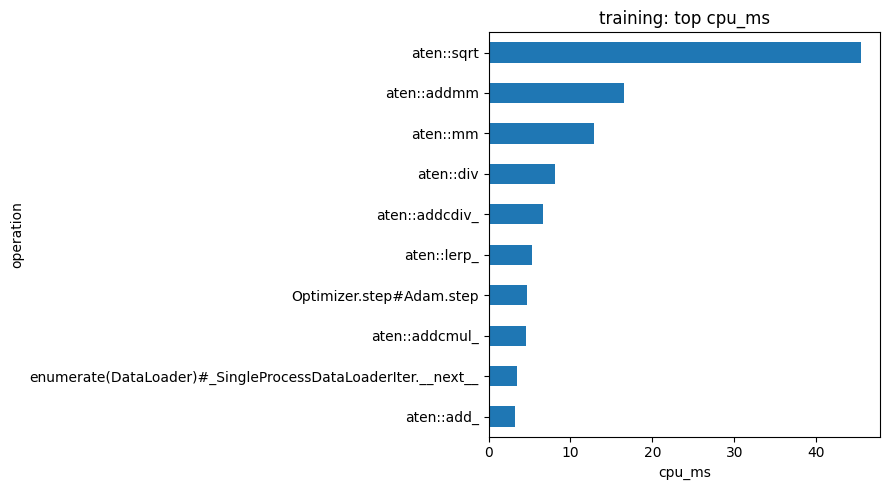

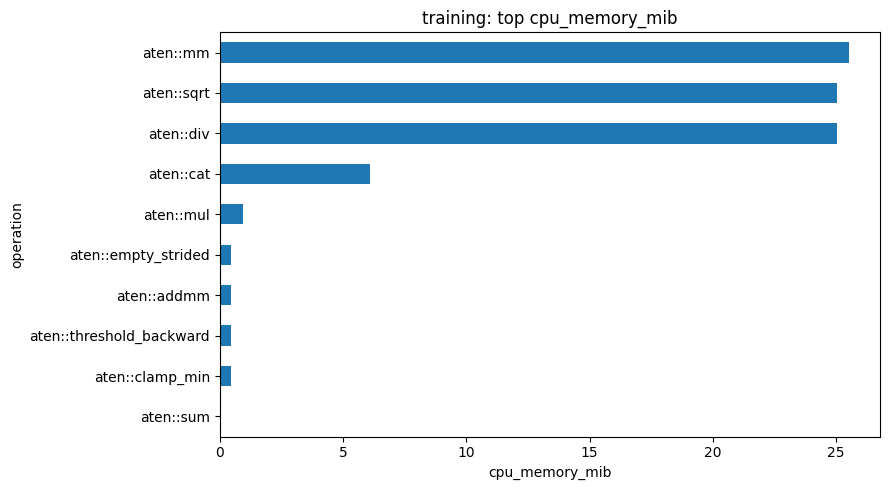

,operation,calls,cpu_ms,device_ms,cpu_memory_mib,device_memory_mib
63,aten::sqrt,30,45.491768,0.0,25.048847,0.0
15,aten::addmm,15,16.483750,0.0,0.469971,0.0
44,aten::mm,25,12.816916,0.0,25.510254,0.0
64,aten::div,30,8.117480,0.0,25.048733,0.0
65,aten::addcdiv_,30,6.623642,0.0,0.000000,0.0


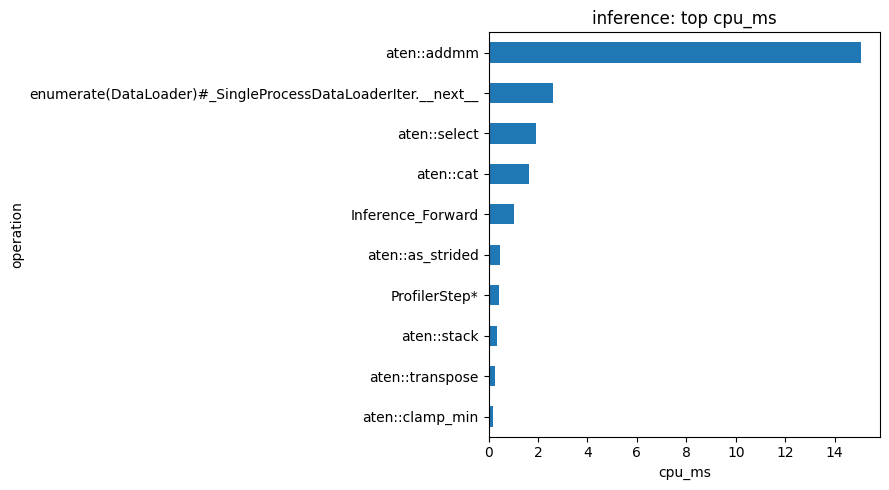

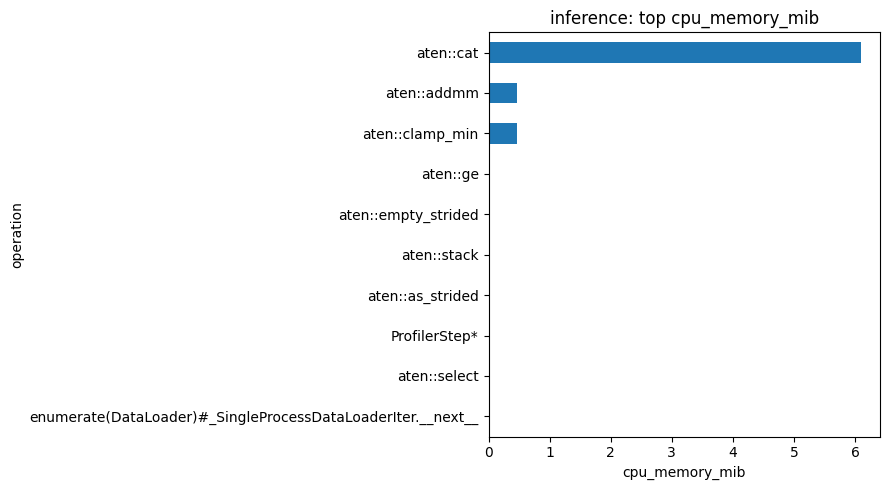

,operation,calls,cpu_ms,device_ms,cpu_memory_mib,device_memory_mib
14,aten::addmm,15,15.077718,0.0,0.469971,0.0
2,enumerate(DataLoader)#_SingleProcessDataLoader...,5,2.590272,0.0,0.000000,0.0
3,aten::select,640,1.903907,0.0,0.000000,0.0
6,aten::cat,10,1.642935,0.0,6.104736,0.0
10,Inference_Forward,5,1.045428,0.0,-0.938721,0.0


In [77]:
for name,frame in [('training',training_ops),('inference',inference_ops)]:
    for metric in ['cpu_ms','device_ms','cpu_memory_mib','device_memory_mib']:
        if metric.startswith('device') and device.type!='cuda': continue
        top=frame.nlargest(10,metric).sort_values(metric)
        if top[metric].max()<=0: continue
        ax=top.plot.barh(x='operation',y=metric,legend=False,figsize=(9,5),title=f'{name}: top {metric}')
        ax.set_xlabel(metric); ax.figure.tight_layout(); ax.figure.savefig(OUT/f'{name}_{metric}.png',dpi=150); plt.show()
    display(frame.nlargest(5,'cpu_ms'))


In [78]:
## 11. Controlled optimisation experiments

,batch,inference,pin,samples,seconds,min_seconds,max_seconds,reviews_per_second,ms_per_review,accuracy,peak_gpu_mib,speedup,time_reduction_pct,accuracy_delta_pp
0,64,False,False,4096,0.2859,0.2732,0.2970,14324.8869,0.0698,0.8918,NaN,1.0000,0.0000,0.0
1,64,True,False,4096,0.2649,0.2562,0.2769,15460.7878,0.0647,0.8918,NaN,1.0793,7.3470,0.0
2,16,True,False,4096,0.3826,0.3606,0.3928,10704.4809,0.0934,0.8918,NaN,0.7473,-33.8214,0.0
3,32,True,False,4096,0.3092,0.2982,0.3271,13246.1254,0.0755,0.8918,NaN,0.9247,-8.1440,0.0
4,128,True,False,4096,0.3603,0.3144,0.3984,11367.6920,0.0880,0.8918,NaN,0.7936,-26.0140,0.0
5,256,True,False,4096,0.3334,0.2137,0.3396,12287.2689,0.0814,0.8918,NaN,0.8578,-16.5832,0.0


Selected configuration: {'batch': 64, 'inference': True, 'pin': False, 'samples': 4096, 'seconds': 0.2649282860002131, 'min_seconds': 0.2562032519999775, 'max_seconds': 0.2769191699990188, 'reviews_per_second': 15460.787754451803, 'ms_per_review': 0.06467975732427078, 'accuracy': 0.891845703125, 'peak_gpu_mib': nan, 'speedup': 1.0792956211629252, 'time_reduction_pct': 7.346978863630094, 'accuracy_delta_pp': 0.0}


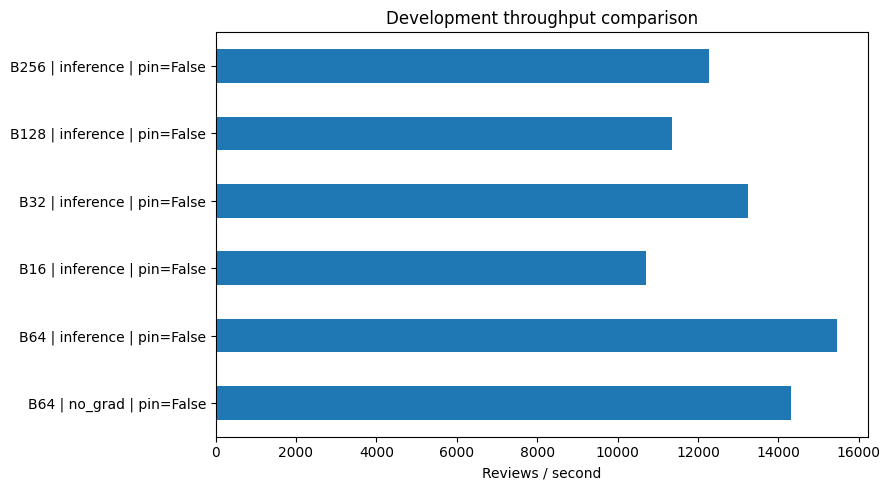

In [79]:
results=[baseline,benchmark(bench_data,inference=True)]
for batch in [16,32,128,256]:
    results.append(benchmark(bench_data,batch=batch,inference=True))
if device.type=='cuda':
    results.append(benchmark(bench_data,batch=64,inference=True,pin=True))
comparison=pd.DataFrame(results)
comparison['speedup']=baseline['seconds']/comparison.seconds
comparison['time_reduction_pct']=100*(1-comparison.seconds/baseline['seconds'])
comparison['accuracy_delta_pp']=100*(comparison.accuracy-baseline['accuracy'])
comparison.to_csv(OUT/'optimisation_results.csv',index=False)
display(comparison.round(4))
valid=comparison[comparison.accuracy_delta_pp.abs()<=0.01]
best=valid.loc[valid.seconds.idxmin()]
print('Selected configuration:',best.to_dict())
labels=[f"B{r.batch} | {'inference' if r.inference else 'no_grad'} | pin={r.pin}" for r in comparison.itertuples()]
ax=pd.Series(comparison.reviews_per_second.values,index=labels).plot.barh(figsize=(9,5),title='Development throughput comparison')
ax.set_xlabel('Reviews / second'); ax.figure.tight_layout(); ax.figure.savefig(OUT/'throughput.png',dpi=150); plt.show()


In [80]:
## 12. Final held-out test evaluation

In [81]:
final_base=benchmark(test_dataset)
final_best=benchmark(test_dataset,batch=int(best.batch),inference=bool(best.inference),pin=bool(best.pin))
final=pd.DataFrame([final_base,final_best],index=['Baseline','Selected'])
final['speedup']=final_base['seconds']/final.seconds
final['time_reduction_pct']=100*(1-final.seconds/final_base['seconds'])
final.to_csv(OUT/'final_comparison.csv'); display(final.round(4))
model.eval(); truth=[]; predictions=[]
with torch.inference_mode():
    for x,y in test_loader:
        predictions.extend((model(x.to(device))>=0).cpu().numpy().ravel())
        truth.extend(y.numpy().ravel())
report=classification_report(truth,predictions,labels=[0,1],target_names=['Negative','Positive'],zero_division=0)
print(report); (OUT/'classification_report.txt').write_text(report)


,batch,inference,pin,samples,seconds,min_seconds,max_seconds,reviews_per_second,ms_per_review,accuracy,peak_gpu_mib,speedup,time_reduction_pct
Baseline,64,False,False,7437,0.5173,0.4871,0.5874,14377.7064,0.0696,0.8889,NaN,1.0000,0.000
Selected,64,True,False,7437,0.4829,0.4675,0.5033,15400.7778,0.0649,0.8889,NaN,1.0712,6.643


              precision    recall  f1-score   support

    Negative       0.89      0.88      0.89      3705
    Positive       0.89      0.89      0.89      3732

    accuracy                           0.89      7437
   macro avg       0.89      0.89      0.89      7437
weighted avg       0.89      0.89      0.89      7437



326

In [82]:
### ################################## End #################################################################################